In [43]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

In [48]:
df = pd.read_parquet('snapshot/snapshot.parquet')
# TODO: Change target_rule to only show number maybe add this to clean data
df['target_rule'] = df['target_rule'].str.extract(r'^(\d+)', expand=False).astype('Int64')
df = df.drop_duplicates()
df.head()

,cifwithcheckdigit,obs_id,obs_seq,m0_monthenddate,m0_arrearsamount,crccreditlimit,due_count,payment_count,m0_total_due_with_arrears,total_paid,target_value,target_rule,new_to_arrears_flag,product_group,m0_start_cd_group,payment_date,days_from_payment,tx_period,collectionsmethodname,transactiondate,trantypedesc,amount,balance,spendgroup,categoryname,exclude_flag
0,C0002093,O0002297,1,2025-09-30,1620.8,38000.0,3,3,7552.95,5932.15,0,6,0,PDM,CD 1,2025-09-25,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-23 15:10:15.625,Card Purchase,-550.00,16816.66,CardTransaction,Groceries,0
1,C0002093,O0002297,1,2025-09-30,1620.8,38000.0,3,3,7552.95,5932.15,0,6,0,PDM,CD 1,2025-09-25,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-23 15:11:31.981,Card Purchase,-550.00,-26132.30,CardTransaction,Groceries,0
2,C0002093,O0002297,1,2025-09-30,1620.8,38000.0,3,3,7552.95,5932.15,0,6,0,PDM,CD 1,2025-09-25,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-24 23:51:59.671,Payment Received,19306.10,21161.03,MoneyIn,Salary,0
3,C0002093,O0002297,1,2025-09-30,1620.8,38000.0,3,3,7552.95,5932.15,0,6,0,PDM,CD 1,2025-09-25,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-24 23:51:59.686,DebiCheck Debit Order,-284.95,20876.08,DebitOrder,Funeral Cover,0
4,C0002093,O0002297,1,2025-09-30,1620.8,38000.0,3,3,7552.95,5932.15,0,6,0,PDM,CD 1,2025-09-25,-92,pre,"Early Debit Order, linked to clients paydate",2025-06-24 23:51:59.703,Registered Debit Order,-125.00,20748.08,DebitOrder,Funeral Cover,0


In [49]:
# Salary table
# Keep salary transactions only
sal = df[df['categoryname'].str.contains('salary', case=False, na=False)].copy()
sal['transactiondate'] = pd.to_datetime(sal['transactiondate'])

# 3. Drop copies created by the overlapping observation windows.
#    balance is included in the key so two genuine identical
#    salaries on the same day aren't merged by accident.
salary_tbl = (
    sal[['cifwithcheckdigit', 'transactiondate', 'amount', 'balance', 'trantypedesc']]
    .drop_duplicates()
    .rename(columns={'cifwithcheckdigit': 'customer_id',
                     'transactiondate': 'pay_date',
                     'amount': 'income_amount'})
    [['customer_id', 'pay_date', 'income_amount']]
    .sort_values(['customer_id', 'pay_date'])
    .reset_index(drop=True)
)

In [50]:
salary_tbl.to_parquet('snapshot/salary.parquet', index=False)

In [47]:
salary = pd.read_parquet('snapshot/salary.parquet')
salary

,customer_id,pay_date,income_amount
0,C0000000,2025-06-24 23:55:56.764,9837.78
1,C0000000,2025-07-25 00:13:20.523,8174.65
2,C0000000,2025-08-22 23:12:03.454,7057.65
3,C0000000,2025-09-25 00:29:26.466,7576.19
4,C0000000,2025-10-24 00:41:51.345,7326.91
...,...,...,...
12919,C0004992,2026-02-12 23:30:43.617,24621.57
12920,C0004994,2025-07-07 15:54:00.780,1000.00
12921,C0004997,2025-10-27 23:34:33.784,16920.44
12922,C0004998,2025-12-11 17:01:38.126,17690.38


In [ ]:
import pandas as pd
import numpy as np

# =====================================================================
# Settings
# =====================================================================
WINDOW = 3            # max days apart for monthly pay days to count as regular
MIN_OCCURRENCES = 3   # similar credits needed to detect a pay frequency
BAND = 0.15           # credits within ~15% of each other count as "similar"
NOT_INCOME = ['interest', 'live better', 'refund', 'reversal', 'own account', 'transfer', 'cash deposit']
EXCLUDE_MONTHS = ['2026-03']   # partial months to drop (YYYY-MM)

# =====================================================================
# 1. Dedupe transactions and set up flags
# =====================================================================
key = ['cifwithcheckdigit', 'transactiondate', 'amount', 'balance', 'trantypedesc']
tx = df.drop_duplicates(subset=key).copy()
tx['transactiondate'] = pd.to_datetime(tx['transactiondate'])
tx['month'] = tx['transactiondate'].dt.to_period('M')
tx = tx[~tx['month'].astype(str).isin(EXCLUDE_MONTHS)].copy()

tx['is_salary'] = tx['categoryname'].str.contains('salary', case=False, na=False)

# Check both category and spend group for non-income words
label_text = (tx['categoryname'].fillna('').astype(str) + ' ' +
              tx['spendgroup'].fillna('').astype(str)).str.lower()
tx['not_income'] = label_text.str.contains('|'.join(NOT_INCOME), regex=True)

tx['has_salary'] = tx.groupby(['cifwithcheckdigit', 'month'])['is_salary'].transform('any')

rename_map = {'cifwithcheckdigit': 'customer_id',
              'transactiondate': 'pay_date',
              'amount': 'income_amount',
              'categoryname': 'category'}
cols = ['customer_id', 'pay_date', 'income_amount', 'category', 'income_type']

# =====================================================================
# 2. Salary table
# =====================================================================
salary_tbl = (tx[tx['is_salary']]
    [['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname']]
    .rename(columns=rename_map)
    .assign(income_type='salary'))

# =====================================================================
# 3. Highest credit per client-month without salary
# =====================================================================
credits = tx[(tx['amount'] > 0) & ~tx['not_income'] & ~tx['has_salary']]

idx = credits.groupby(['cifwithcheckdigit', 'month'])['amount'].idxmax()
est_tbl = (credits.loc[idx, ['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname', 'month']]
    .rename(columns=rename_map))

# Regular vs irregular based on day of month
def max_day_gap(days):
    d = days.to_numpy()
    diff = np.abs(d[:, None] - d[None, :])
    diff = np.minimum(diff, 31 - diff)  # 31st and 1st are 1 day apart
    return diff.max()

est_tbl['day'] = est_tbl['pay_date'].dt.day
grp = est_tbl.groupby('customer_id')['day']
est_tbl['n_months'] = grp.transform('size')
est_tbl['day_gap'] = grp.transform(max_day_gap)
est_tbl['income_type'] = np.where(
    (est_tbl['n_months'] >= 2) & (est_tbl['day_gap'] <= WINDOW),
    'estimated_regular', 'estimated_irregular')

# =====================================================================
# 4. Pay frequency detection (weekly / fortnightly / monthly)
# =====================================================================
inc = tx[(tx['amount'] > 0) & (~tx['not_income'] | tx['is_salary'])][
    ['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname', 'month', 'has_salary']].copy()

inc['amount_band'] = np.round(np.log(inc['amount']) / np.log(1 + BAND)).astype(int)
inc = inc.sort_values(['cifwithcheckdigit', 'amount_band', 'transactiondate'])
inc['gap'] = inc.groupby(['cifwithcheckdigit', 'amount_band'])['transactiondate'].diff().dt.days
inc['weekday'] = inc['transactiondate'].dt.dayofweek

pattern = inc.groupby(['cifwithcheckdigit', 'amount_band']).agg(
    n=('amount', 'size'),
    total=('amount', 'sum'),
    median_gap=('gap', 'median'),
    weekday_share=('weekday', lambda w: w.value_counts(normalize=True).iloc[0]),
).reset_index()
pattern = pattern[pattern['n'] >= MIN_OCCURRENCES]

pattern['pay_frequency'] = np.select(
    [pattern['median_gap'].between(5, 9),
     pattern['median_gap'].between(12, 16),
     pattern['median_gap'].between(26, 35)],
    ['weekly', 'fortnightly', 'monthly'], default='irregular')

main = (pattern.sort_values('total', ascending=False)
    .drop_duplicates('cifwithcheckdigit'))

pay_freq = (main.rename(columns={'cifwithcheckdigit': 'customer_id'})
    [['customer_id', 'pay_frequency', 'median_gap', 'weekday_share', 'n']]
    .sort_values('customer_id').reset_index(drop=True))

# =====================================================================
# 5. Replace single-max rows with all payments for weekly/fortnightly clients
# =====================================================================
multi = main[main['pay_frequency'].isin(['weekly', 'fortnightly'])][
    ['cifwithcheckdigit', 'amount_band', 'pay_frequency']]

freq_tbl = (inc.merge(multi, on=['cifwithcheckdigit', 'amount_band'])
    .loc[lambda d: ~d['has_salary']]
    .rename(columns=rename_map)
    .assign(income_type=lambda d: 'estimated_' + d['pay_frequency']))

replaced = freq_tbl[['customer_id', 'month']].drop_duplicates()
est_keep = (est_tbl
    .merge(replaced, on=['customer_id', 'month'], how='left', indicator=True)
    .loc[lambda d: d['_merge'] == 'left_only'])

# =====================================================================
# 6. Final income table
# =====================================================================
income_tbl = (pd.concat([salary_tbl[cols], est_keep[cols], freq_tbl[cols]])
    .merge(pay_freq[['customer_id', 'pay_frequency']], on='customer_id', how='left')
    .fillna({'pay_frequency': 'unknown'})
    .sort_values(['customer_id', 'pay_date'])
    .reset_index(drop=True))
income_tbl['month'] = income_tbl['pay_date'].dt.to_period('M')

# Check: no excluded categories left
leftover = income_tbl['category'].fillna('').str.lower().str.contains('|'.join(NOT_INCOME))
print('Excluded categories remaining:', leftover.sum())

# =====================================================================
# 7. Monthly totals (for modelling)
# =====================================================================
monthly_income = (income_tbl
    .groupby(['customer_id', 'month'], as_index=False)
    .agg(income=('income_amount', 'sum'),
         n_payments=('income_amount', 'size'),
         pay_frequency=('pay_frequency', 'first')))

print(income_tbl['income_type'].value_counts())
income_tbl.head(20)

Excluded categories remaining: 0
income_type
estimated_irregular      14122
salary                   12884
estimated_fortnightly     2671
estimated_weekly          2640
estimated_regular         1545
Name: count, dtype: int64


,customer_id,pay_date,income_amount,category,income_type,pay_frequency,month
0,C0000000,2025-06-24 23:55:56.764,9837.78,Salary,salary,irregular,2025-06
1,C0000000,2025-07-25 00:13:20.523,8174.65,Salary,salary,irregular,2025-07
2,C0000000,2025-08-22 23:12:03.454,7057.65,Salary,salary,irregular,2025-08
3,C0000000,2025-09-25 00:29:26.466,7576.19,Salary,salary,irregular,2025-09
4,C0000000,2025-10-24 00:41:51.345,7326.91,Salary,salary,irregular,2025-10
5,C0000000,2025-11-24 21:53:28.221,7236.64,Salary,salary,irregular,2025-11
6,C0000000,2025-12-18 23:00:21.909,9780.51,Salary,salary,irregular,2025-12
7,C0000000,2026-01-22 23:17:29.320,8027.27,Salary,salary,irregular,2026-01
8,C0000001,2025-10-26 23:39:46.475,33276.84,Salary,salary,irregular,2025-10
9,C0000001,2025-11-26 23:26:32.653,29419.64,Salary,salary,irregular,2025-11


In [32]:
income_tbl['category'].unique().tolist()

['Salary',
 'Other Income',
 'Account Payment Received',
 'Uncategorised',
 'Payment Received',
 'Cash Deposit',
 'Pension',
 'Credit Card Payments',
 'Wage',
 'UIF Received',
 'Funeral Cover',
 'Loan Payments',
 'Automatic Savings',
 'Internet',
 'Vehicle Insurance',
 'Savings',
 'Betting/Lottery',
 'Other Insurance',
 'Banking Rewards',
 'Vehicle Payments',
 'Home Loan Payments',
 'Furniture & Appliances',
 'Cash Withdrawal',
 'Loans',
 'Clothing & Shoes',
 'Telephone',
 'Digital Payments',
 'Rental Income',
 'Store Account Payments',
 'Commission',
 'Life Insurance',
 'Allowance',
 'Other Personal & Family',
 'Investment Income',
 'Insurance Payout',
 'Vehicle Tracking',
 'Legal Fees',
 'Bonus',
 'Other Communication',
 'Home Insurance',
 'Cellphone',
 'Other Loans & Accounts',
 'Education',
 'Personal Care',
 'Children & Dependants',
 'Partner Rewards',
 'Other Household',
 'Investments',
 'Other Medical',
 'Digital Subscriptions',
 'Fuel',
 'Child Support',
 'Medical Aid',
 'Secur

In [36]:
import pandas as pd
import numpy as np

# =====================================================================
# Settings
# =====================================================================
WINDOW = 3              # max days apart for monthly pay days to count as regular
MIN_OCCURRENCES = 3     # similar credits needed to detect a pay frequency
BAND = 0.15             # credits within ~15% of each other count as "similar"
EXCLUDE_MONTHS = ['2026-03']   # partial months to drop (YYYY-MM)
PAY_MIN_SHARE = 0.5     # a payment is a "pay day" if >= 50% of client's median payment
HALF_LIFE = 1           # months; recency weight halves every HALF_LIFE months back

SALARY_CATS = ['Salary', 'Wage']
INCOME_CATS = ['Pension', 'UIF Received', 'Commission', 'Allowance',
               'Child Support', 'Rental Income', 'Other Income']
AMBIGUOUS_CATS = ['Payment Received']
NOT_SPEND = ['Savings', 'Automatic Savings', 'Investments', 'Other Savings & Investments']

TYPE_PRIORITY = ['salary', 'estimated_weekly', 'estimated_fortnightly',
                 'estimated_regular', 'estimated_irregular']

# =====================================================================
# 1. Dedupe transactions and set up flags
# =====================================================================
key = ['cifwithcheckdigit', 'transactiondate', 'amount', 'balance', 'trantypedesc']
tx = df.drop_duplicates(subset=key).copy()
tx['transactiondate'] = pd.to_datetime(tx['transactiondate'])
tx['month'] = tx['transactiondate'].dt.to_period('M')
tx = tx[~tx['month'].astype(str).isin(EXCLUDE_MONTHS)].copy()

tx['is_salary'] = tx['categoryname'].isin(SALARY_CATS)
is_transfer = tx['spendgroup'].fillna('').astype(str).str.contains('transfer', case=False)
tx['is_income'] = tx['categoryname'].isin(INCOME_CATS + AMBIGUOUS_CATS) & ~is_transfer
tx['has_salary'] = tx.groupby(['cifwithcheckdigit', 'month'])['is_salary'].transform('any')

rename_map = {'cifwithcheckdigit': 'customer_id',
              'transactiondate': 'pay_date',
              'amount': 'income_amount',
              'categoryname': 'category'}
cols = ['customer_id', 'pay_date', 'income_amount', 'category', 'income_type']

# =====================================================================
# 2. Salary table
# =====================================================================
salary_tbl = (tx[tx['is_salary'] & (tx['amount'] > 0)]
    [['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname']]
    .rename(columns=rename_map)
    .assign(income_type='salary'))

# =====================================================================
# 3. Highest income credit per client-month without salary
# =====================================================================
credits = tx[(tx['amount'] > 0) & tx['is_income'] & ~tx['has_salary']]

idx = credits.groupby(['cifwithcheckdigit', 'month'])['amount'].idxmax()
est_tbl = (credits.loc[idx, ['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname', 'month']]
    .rename(columns=rename_map))

def max_day_gap(days):
    d = days.to_numpy()
    diff = np.abs(d[:, None] - d[None, :])
    diff = np.minimum(diff, 31 - diff)  # 31st and 1st are 1 day apart
    return diff.max()

est_tbl['day'] = est_tbl['pay_date'].dt.day
grp = est_tbl.groupby('customer_id')['day']
est_tbl['n_months'] = grp.transform('size')
est_tbl['day_gap'] = grp.transform(max_day_gap)
est_tbl['income_type'] = np.where(
    (est_tbl['n_months'] >= 2) & (est_tbl['day_gap'] <= WINDOW),
    'estimated_regular', 'estimated_irregular')

# =====================================================================
# 4. Pay frequency detection (weekly / fortnightly / monthly)
# =====================================================================
inc = tx[(tx['amount'] > 0) & (tx['is_income'] | tx['is_salary'])][
    ['cifwithcheckdigit', 'transactiondate', 'amount', 'categoryname', 'month', 'has_salary']].copy()

inc['amount_band'] = np.round(np.log(inc['amount']) / np.log(1 + BAND)).astype(int)
inc = inc.sort_values(['cifwithcheckdigit', 'amount_band', 'transactiondate'])
inc['gap'] = inc.groupby(['cifwithcheckdigit', 'amount_band'])['transactiondate'].diff().dt.days
inc['weekday'] = inc['transactiondate'].dt.dayofweek

pattern = inc.groupby(['cifwithcheckdigit', 'amount_band']).agg(
    n=('amount', 'size'),
    total=('amount', 'sum'),
    median_gap=('gap', 'median'),
    weekday_share=('weekday', lambda w: w.value_counts(normalize=True).iloc[0]),
).reset_index()
pattern = pattern[pattern['n'] >= MIN_OCCURRENCES]

pattern['pay_frequency'] = np.select(
    [pattern['median_gap'].between(5, 9),
     pattern['median_gap'].between(12, 16),
     pattern['median_gap'].between(26, 35)],
    ['weekly', 'fortnightly', 'monthly'], default='irregular')

main = pattern.sort_values('total', ascending=False).drop_duplicates('cifwithcheckdigit')

pay_freq = (main.rename(columns={'cifwithcheckdigit': 'customer_id'})
    [['customer_id', 'pay_frequency', 'median_gap', 'weekday_share', 'n']]
    .sort_values('customer_id').reset_index(drop=True))

# =====================================================================
# 5. Replace single-max rows with all payments for weekly/fortnightly clients
# =====================================================================
multi = main[main['pay_frequency'].isin(['weekly', 'fortnightly'])][
    ['cifwithcheckdigit', 'amount_band', 'pay_frequency']]

freq_tbl = (inc.merge(multi, on=['cifwithcheckdigit', 'amount_band'])
    .loc[lambda d: ~d['has_salary']]
    .rename(columns=rename_map)
    .assign(income_type=lambda d: 'estimated_' + d['pay_frequency']))

replaced = freq_tbl[['customer_id', 'month']].drop_duplicates()
est_keep = (est_tbl
    .merge(replaced, on=['customer_id', 'month'], how='left', indicator=True)
    .loc[lambda d: d['_merge'] == 'left_only'])

# =====================================================================
# 6. Income table (same-day payments combined)
# =====================================================================
income_tbl = pd.concat([salary_tbl[cols], est_keep[cols], freq_tbl[cols]])
income_tbl['pay_date'] = income_tbl['pay_date'].dt.normalize()
income_tbl['type_rank'] = income_tbl['income_type'].map({t: i for i, t in enumerate(TYPE_PRIORITY)})

income_tbl = (income_tbl
    .sort_values(['customer_id', 'pay_date', 'type_rank'])
    .groupby(['customer_id', 'pay_date'], as_index=False)
    .agg(income_amount=('income_amount', 'sum'),
         n_payments=('income_amount', 'size'),
         category=('category', lambda c: ', '.join(sorted(c.dropna().unique()))),
         income_type=('income_type', 'first')))

income_tbl = (income_tbl
    .merge(pay_freq[['customer_id', 'pay_frequency']], on='customer_id', how='left')
    .fillna({'pay_frequency': 'unknown'})
    .sort_values(['customer_id', 'pay_date'])
    .reset_index(drop=True))
income_tbl['month'] = income_tbl['pay_date'].dt.to_period('M')

allowed = SALARY_CATS + INCOME_CATS + AMBIGUOUS_CATS
cat_check = income_tbl['category'].str.split(', ').explode()
print('Unexpected categories:', (~cat_check.isin(allowed) & cat_check.ne('')).sum())

# =====================================================================
# 7. Monthly totals and one row per customer
# =====================================================================
monthly = (income_tbl
    .groupby(['customer_id', 'month'], as_index=False)
    .agg(income=('income_amount', 'sum'),
         n_payments=('n_payments', 'sum'),
         income_type=('income_type', lambda t: min(t, key=TYPE_PRIORITY.index))))

# Months each client actually appears in the data
covered = (tx[['cifwithcheckdigit', 'month']].drop_duplicates()
    .rename(columns={'cifwithcheckdigit': 'customer_id'}))
monthly = covered.merge(monthly, on=['customer_id', 'month'], how='left')
monthly['income'] = monthly['income'].fillna(0)
monthly['n_payments'] = monthly['n_payments'].fillna(0).astype(int)
monthly['income_type'] = monthly['income_type'].fillna('none')
monthly = monthly.sort_values(['customer_id', 'month']).reset_index(drop=True)

wide = monthly.pivot(index='customer_id', columns='month',
                     values=['income', 'n_payments', 'income_type'])
wide.columns = [f'{val}_{m}' for val, m in wide.columns]
wide = wide[sorted(wide.columns, key=lambda c: (c.rsplit('_', 1)[1], c))]

summary = monthly.groupby('customer_id').agg(
    months_observed=('month', 'size'),
    months_with_income=('income', lambda x: (x > 0).sum()),
    avg_monthly_income=('income', 'mean'),
    income_cv=('income', lambda x: x.std() / x.mean() if x.mean() > 0 else np.nan))
summary = (summary
    .join(pay_freq.set_index('customer_id')['pay_frequency'])
    .fillna({'pay_frequency': 'unknown'}))

# =====================================================================
# 8. Pay cycles and spending
# =====================================================================
pay = income_tbl[['customer_id', 'pay_date', 'income_amount']].copy()
med = pay.groupby('customer_id')['income_amount'].transform('median')
pay_events = (pay[pay['income_amount'] >= PAY_MIN_SHARE * med]
    .sort_values(['customer_id', 'pay_date']).copy())
pay_events['next_pay'] = pay_events.groupby('customer_id')['pay_date'].shift(-1)
pay_events['cycle_days'] = (pay_events['next_pay'] - pay_events['pay_date']).dt.days
cycles = pay_events.dropna(subset=['next_pay'])

spend_mask = (tx['amount'] < 0) & ~is_transfer & ~tx['categoryname'].isin(NOT_SPEND)
spend = (tx.loc[spend_mask, ['cifwithcheckdigit', 'transactiondate', 'amount']]
    .rename(columns={'cifwithcheckdigit': 'customer_id'})
    .assign(spend=lambda d: -d['amount'])
    .sort_values('transactiondate'))

s = pd.merge_asof(spend, cycles.sort_values('pay_date'),
                  left_on='transactiondate', right_on='pay_date',
                  by='customer_id', direction='backward')
s = s[s['pay_date'].notna() & (s['transactiondate'] < s['next_pay'])].copy()
s['days_after_pay'] = (s['transactiondate'] - s['pay_date']).dt.days
s = s.sort_values(['customer_id', 'pay_date', 'transactiondate'])
s['cum_share'] = s.groupby(['customer_id', 'pay_date'])['spend'].cumsum() / s['income_amount']
s['spend_first3'] = s['spend'].where(s['days_after_pay'] < 3, 0)

agg = s.groupby(['customer_id', 'pay_date']).agg(
    spend=('spend', 'sum'),
    spend_first3=('spend_first3', 'sum'))
half = (s[s['cum_share'] >= 0.5]
    .groupby(['customer_id', 'pay_date'])['days_after_pay'].min()
    .rename('days_to_half'))

per_cycle = (cycles.set_index(['customer_id', 'pay_date'])
    .join(agg).join(half)
    .fillna({'spend': 0, 'spend_first3': 0}))
per_cycle['days_to_half'] = per_cycle['days_to_half'].fillna(per_cycle['cycle_days'])
per_cycle['spend_ratio'] = per_cycle['spend'] / per_cycle['income_amount']
per_cycle['spend_per_day'] = per_cycle['spend'] / per_cycle['cycle_days']
per_cycle['frac_to_half'] = per_cycle['days_to_half'] / per_cycle['cycle_days']
per_cycle['first3_share'] = per_cycle['spend_first3'] / per_cycle['income_amount']

# =====================================================================
# 9. Customer-level features
# =====================================================================
# Spending between pay days + how quickly pay is spent
spend_feats = per_cycle.groupby('customer_id').agg(
    n_cycles=('spend', 'size'),
    avg_spend_between_pays=('spend', 'mean'),
    avg_spend_ratio=('spend_ratio', 'mean'),
    avg_spend_per_day=('spend_per_day', 'mean'),
    avg_days_to_half=('days_to_half', 'mean'),
    avg_frac_to_half=('frac_to_half', 'mean'),
    avg_first3_share=('first3_share', 'mean'))

# Pay day regularity
pay_events['gap'] = pay_events.groupby('customer_id')['pay_date'].diff().dt.days
reg_feats = pay_events.groupby('customer_id')['gap'].agg(
    pay_gap_mean='mean', pay_gap_std='std')
reg_feats['pay_gap_cv'] = reg_feats['pay_gap_std'] / reg_feats['pay_gap_mean']

# Change in income between months
mean_inc = monthly.groupby('customer_id')['income'].transform('mean')
monthly['rel_change'] = (monthly.groupby('customer_id')['income'].diff() / mean_inc
                         ).replace([np.inf, -np.inf], np.nan)

def trend(x):
    if len(x) < 2 or x.mean() == 0:
        return np.nan
    return np.polyfit(np.arange(len(x)), x.to_numpy(float), 1)[0] / x.mean()

chg_feats = monthly.groupby('customer_id').agg(
    avg_abs_income_change=('rel_change', lambda x: x.abs().mean()),
    last_income_change=('rel_change', 'last'),
    income_trend=('income', trend))

# Recency-weighted income
month_num = monthly['month'].dt.year * 12 + monthly['month'].dt.month
months_ago = month_num.groupby(monthly['customer_id']).transform('max') - month_num
monthly['w'] = 0.5 ** (months_ago / HALF_LIFE)
monthly['w_income'] = monthly['income'] * monthly['w']

sums = monthly.groupby('customer_id')[['w_income', 'w']].sum()
recency_feats = pd.DataFrame({'recency_weighted_income': sums['w_income'] / sums['w']})
recency_feats['recent_vs_avg_income'] = (
    recency_feats['recency_weighted_income'] / monthly.groupby('customer_id')['income'].mean()
).replace([np.inf, -np.inf], np.nan)

# =====================================================================
# 10. Final table: one row per customer
# =====================================================================
customer_features = (summary
    .join([reg_feats, spend_feats, chg_feats, recency_feats, wide])
    .reset_index())

print(income_tbl['income_type'].value_counts())
print('Customers:', len(customer_features), '| Columns:', customer_features.shape[1])
customer_features.head()

Unexpected categories: 0
income_type
salary                   12136
estimated_irregular      12041
estimated_regular         1547
estimated_weekly          1438
estimated_fortnightly      969
Name: count, dtype: int64
Customers: 4999 | Columns: 51


,customer_id,months_observed,months_with_income,avg_monthly_income,income_cv,pay_frequency,pay_gap_mean,pay_gap_std,pay_gap_cv,n_cycles,avg_spend_between_pays,avg_spend_ratio,avg_spend_per_day,avg_days_to_half,avg_frac_to_half,avg_first3_share,avg_abs_income_change,last_income_change,income_trend,recency_weighted_income,recent_vs_avg_income,income_2025-05,income_type_2025-05,n_payments_2025-05,income_2025-06,income_type_2025-06,n_payments_2025-06,income_2025-07,income_type_2025-07,n_payments_2025-07,income_2025-08,income_type_2025-08,n_payments_2025-08,income_2025-09,income_type_2025-09,n_payments_2025-09,income_2025-10,income_type_2025-10,n_payments_2025-10,income_2025-11,income_type_2025-11,n_payments_2025-11,income_2025-12,income_type_2025-12,n_payments_2025-12,income_2026-01,income_type_2026-01,n_payments_2026-01,income_2026-02,income_type_2026-02,n_payments_2026-02
0,C0000000,9,8,7224.177778,0.401386,irregular,30.285714,3.728909,0.123124,7.0,11125.714286,1.379394,374.998484,2.285714,0.072244,0.634117,0.276201,-1.111167,-0.080025,4143.392250,0.573545,NaN,NaN,NaN,9837.78,salary,1,8174.65,salary,1,7057.65,salary,1,7576.19,salary,1,7326.91,salary,1,7236.64,salary,1,9780.51,salary,1,8027.27,salary,1,0.0,none,0
1,C0000001,5,5,43529.368000,0.485119,irregular,30.750000,6.130525,0.199367,4.0,60791.560000,1.366451,1988.021789,1.500000,0.049707,0.803817,0.576455,-1.035880,0.129501,47235.412903,1.085139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33276.84,salary,1,29419.64,salary,1,38357.24,salary,2,80842.15,salary,2,35750.97,salary,1
2,C0000002,5,4,4374.004000,0.999606,irregular,59.000000,NaN,NaN,1.0,24693.080000,2.469308,418.526780,8.000000,0.135593,0.115400,1.329443,-0.571559,-0.431413,2088.388387,0.477455,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000.0,estimated_regular,1,1370.02,estimated_regular,1,8000.0,estimated_regular,1,2500.0,estimated_regular,1,0.0,none,0
3,C0000003,8,8,1368.336250,1.163053,monthly,31.500000,16.176114,0.513527,4.0,8907.420000,7.392817,291.857545,0.000000,0.000000,1.690003,0.754481,3.023153,0.317442,3043.162039,2.223987,NaN,NaN,NaN,110.0,estimated_irregular,1,400.0,estimated_irregular,1,1200.0,estimated_irregular,1,1100.0,estimated_irregular,1,1500.0,estimated_irregular,1,500.0,estimated_irregular,1,1000.0,estimated_irregular,1,5136.69,estimated_irregular,1,NaN,NaN,NaN
4,C0000004,5,5,12818.014000,0.375221,monthly,13.428571,11.631239,0.866156,7.0,12333.341429,1.781409,1329.204185,1.000000,0.146131,1.074876,0.393338,-0.394925,-0.137903,9882.273226,0.770968,NaN,NaN,NaN,11439.89,salary,1,18992.51,salary,5,15839.73,salary,3,11440.05,salary,1,6377.89,salary,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


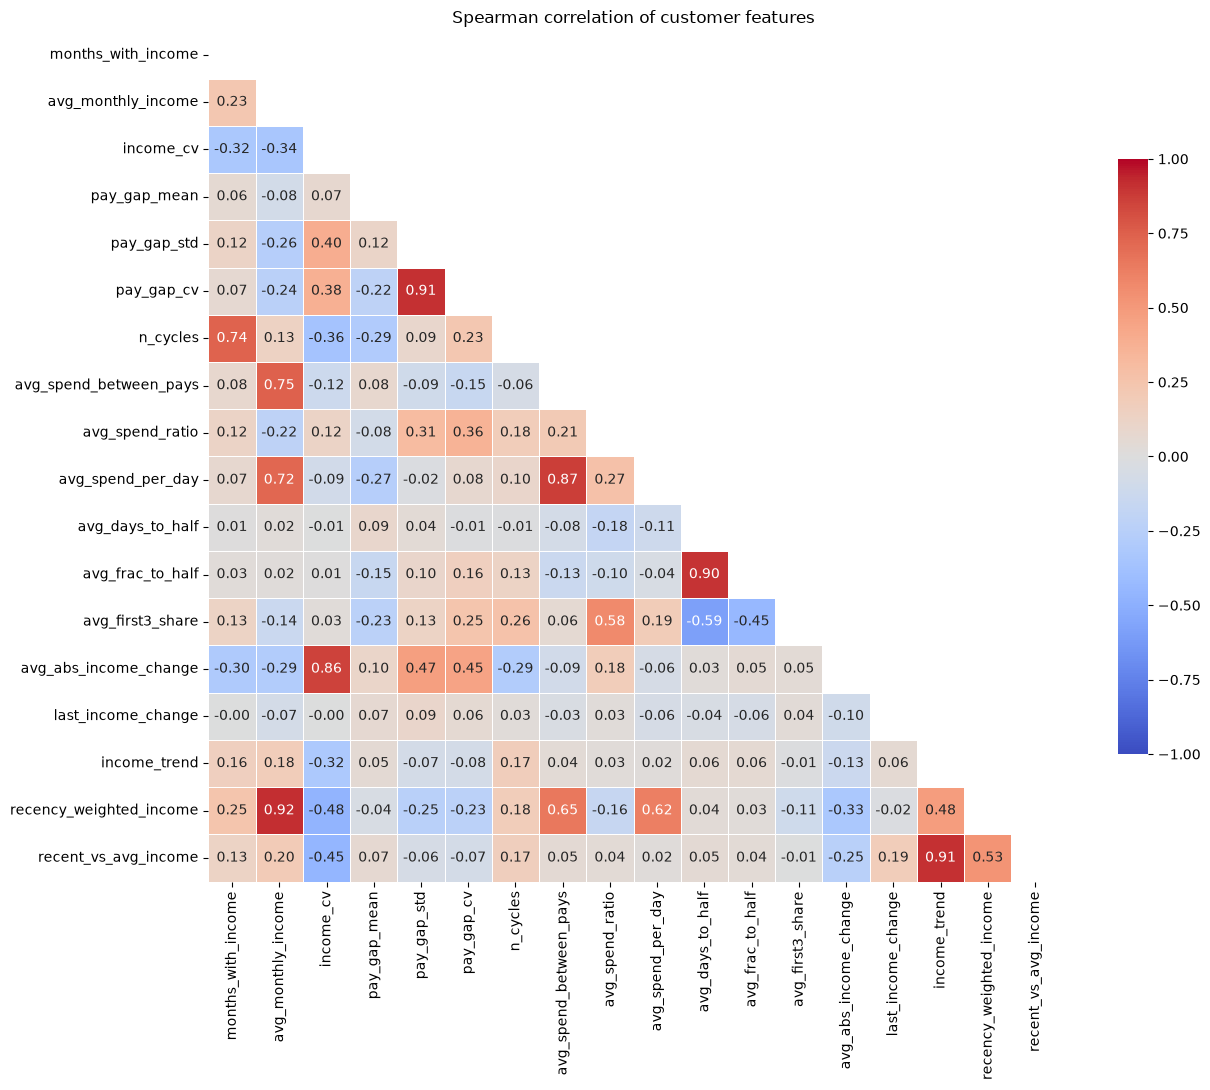

                   feature_1               feature_2      corr
289  recency_weighted_income      avg_monthly_income  0.919536
94                pay_gap_cv             pay_gap_std  0.912409
321     recent_vs_avg_income            income_trend  0.910165
208         avg_frac_to_half        avg_days_to_half  0.903832
169        avg_spend_per_day  avg_spend_between_pays  0.868989
236    avg_abs_income_change               income_cv  0.855987
127   avg_spend_between_pays      avg_monthly_income  0.748765
108                 n_cycles      months_with_income  0.738711
163        avg_spend_per_day      avg_monthly_income  0.723686


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [
    'months_with_income', 'avg_monthly_income', 'income_cv',
    'pay_gap_mean', 'pay_gap_std', 'pay_gap_cv',
    'n_cycles', 'avg_spend_between_pays', 'avg_spend_ratio', 'avg_spend_per_day',
    'avg_days_to_half', 'avg_frac_to_half', 'avg_first3_share',
    'avg_abs_income_change', 'last_income_change', 'income_trend',
    'recency_weighted_income', 'recent_vs_avg_income',
]

# Spearman: based on ranks, so skewed rand amounts and outliers don't dominate
corr = customer_features[feature_cols].corr(method='spearman')

mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.7})
plt.title('Spearman correlation of customer features')
plt.tight_layout()
plt.show()

# List the strongly correlated pairs
pairs = (corr.where(~mask).stack()
         .rename('corr').reset_index()
         .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))
print(pairs[pairs['corr'].abs() >= 0.7].sort_values('corr', key=abs, ascending=False))

Clustering 4,319 of 4,999 customers (680 have no detectable income / too few pay cycles)


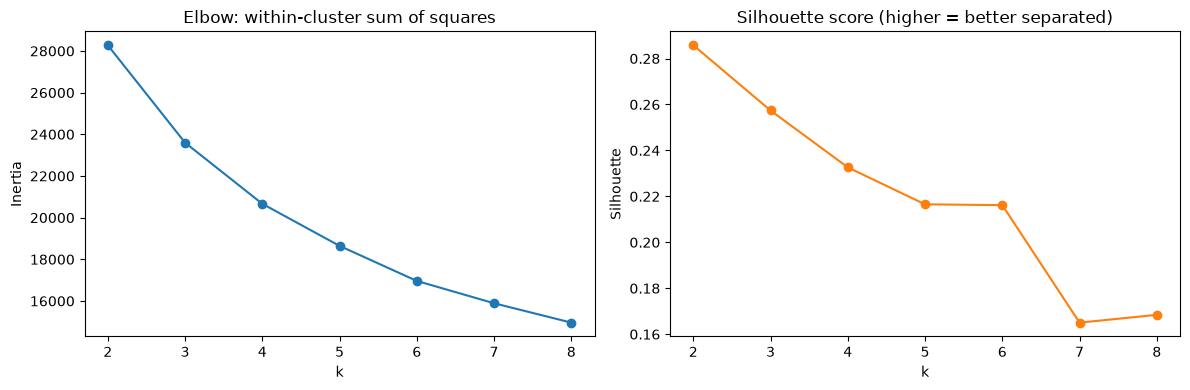

,n_customers,share_%,avg_monthly_income,income_cv,recent_vs_avg_income,pay_gap_cv,avg_spend_ratio,avg_spend_per_day,avg_frac_to_half,avg_first3_share
cluster,,,,,,,,,,
0,2753,63.7,10385.78,0.59,0.91,0.19,2.10,1003.70,0.03,1.08
1,1316,30.5,2588.67,1.00,0.65,0.51,2.54,328.25,0.04,1.09
2,250,5.8,2648.66,1.06,0.83,0.71,17.17,1109.06,0.02,4.65


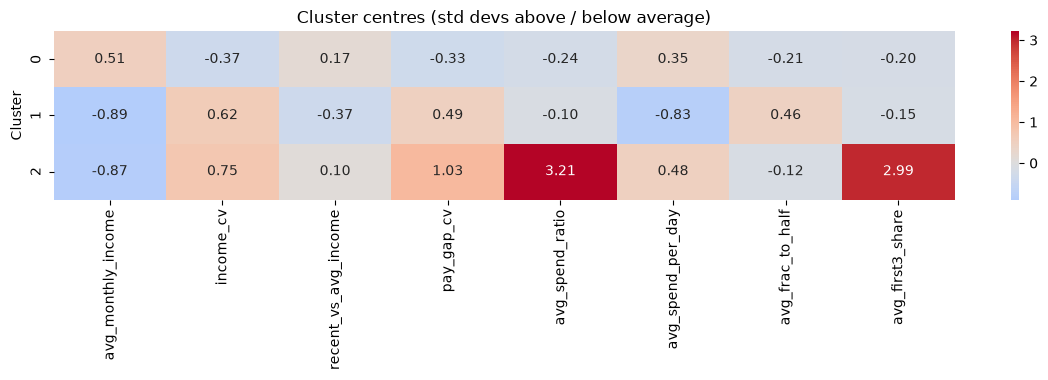

Overall bad rate: 51.9%


,n_obs,bad_rate
cluster,,
0,5440,37.2
1,3261,64.3
2,516,55.6


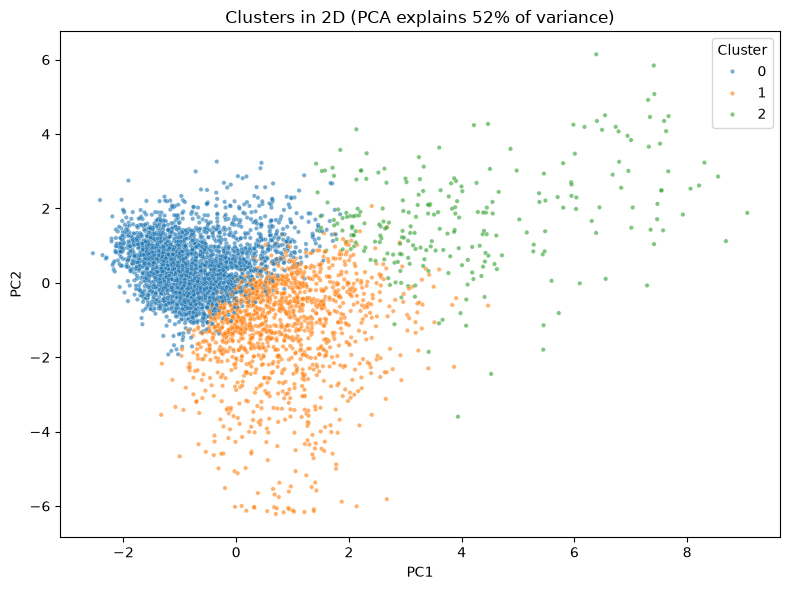

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================================
# Settings
# =====================================================================
# One feature per correlated group; adjust after checking the heatmap
CLUSTER_FEATURES = [
    'avg_monthly_income',     # income level
    'income_cv',              # income volatility
    'recent_vs_avg_income',   # income direction (recent vs usual)
    'pay_gap_cv',             # pay day regularity
    'avg_spend_ratio',        # spend vs pay
    'avg_spend_per_day',      # spending level
    'avg_frac_to_half',       # how quickly pay is spent
    'avg_first3_share',       # spending straight after pay day
]
LOG_FEATURES = ['avg_monthly_income', 'avg_spend_per_day']   # skewed rand amounts
K = 3                 # final number of clusters (choose using step 3)
RANDOM_STATE = 42

# =====================================================================
# 1. Select customers with complete features
# =====================================================================
data = customer_features[['customer_id'] + CLUSTER_FEATURES].dropna().copy()
print(f'Clustering {len(data):,} of {len(customer_features):,} customers '
      f'({len(customer_features) - len(data):,} have no detectable income / too few pay cycles)')

# =====================================================================
# 2. Prepare features: log, clip outliers, scale
# =====================================================================
X = data[CLUSTER_FEATURES].copy()

for col in LOG_FEATURES:
    X[col] = np.log1p(X[col].clip(lower=0))       # compress large rand values

X = X.clip(lower=X.quantile(0.01), upper=X.quantile(0.99), axis=1)   # limit extreme values

X_scaled = StandardScaler().fit_transform(X)      # every feature: mean 0, std 1

# =====================================================================
# 3. Choose k: elbow + silhouette
# =====================================================================
ks = range(2, 9)
inertias, silhouettes = [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_,
                                        sample_size=min(10_000, len(X_scaled)),
                                        random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker='o')
axes[0].set(title='Elbow: within-cluster sum of squares', xlabel='k', ylabel='Inertia')
axes[1].plot(ks, silhouettes, marker='o', color='tab:orange')
axes[1].set(title='Silhouette score (higher = better separated)', xlabel='k', ylabel='Silhouette')
plt.tight_layout()
plt.show()

# =====================================================================
# 4. Fit final model
# =====================================================================
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
data['cluster'] = kmeans.labels_

# =====================================================================
# 5. Profile the clusters
# =====================================================================
# 5a. Size and median of each feature, in original units
profile = data.groupby('cluster')[CLUSTER_FEATURES].median().round(2)
sizes = data['cluster'].value_counts().sort_index()
profile.insert(0, 'n_customers', sizes)
profile.insert(1, 'share_%', (sizes / sizes.sum() * 100).round(1))
display(profile)

# 5b. Cluster centres in standardised units: easiest way to label clusters
centres = pd.DataFrame(kmeans.cluster_centers_, columns=CLUSTER_FEATURES)
plt.figure(figsize=(12, 0.8 * K + 1.5))
sns.heatmap(centres, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster centres (std devs above / below average)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

# =====================================================================
# 6. Validate: bad rate per cluster
# =====================================================================
obs = (df[df['exclude_flag'] == 0]
       [['obs_id', 'cifwithcheckdigit', 'target_value']]
       .drop_duplicates('obs_id')
       .rename(columns={'cifwithcheckdigit': 'customer_id'})
       .merge(data[['customer_id', 'cluster']], on='customer_id', how='left'))

obs['cluster'] = obs['cluster'].astype('Int64').astype(str).replace('<NA>', 'no income')

bad_rates = (obs.groupby('cluster')['target_value']
             .agg(n_obs='size', bad_rate='mean')
             .assign(bad_rate=lambda d: (d['bad_rate'] * 100).round(1)))
print(f"Overall bad rate: {obs['target_value'].mean() * 100:.1f}%")
display(bad_rates)

# =====================================================================
# 7. 2D view of the clusters (PCA)
# =====================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
sample = np.random.default_rng(RANDOM_STATE).choice(len(coords), min(5_000, len(coords)), replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[sample, 0], y=coords[sample, 1],
                hue=data['cluster'].to_numpy()[sample], palette='tab10', s=10, alpha=0.6)
plt.title(f'Clusters in 2D (PCA explains {pca.explained_variance_ratio_.sum() * 100:.0f}% of variance)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()